<a href="https://colab.research.google.com/github/nuruyar/ai_master_computervision/blob/main/lab_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from PIL import Image
from pylab import *
import numpy as np
import matplotlib.pyplot as plt
import math
import scipy.ndimage as snd
from scipy.ndimage import *
from skimage import feature
import cv2

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


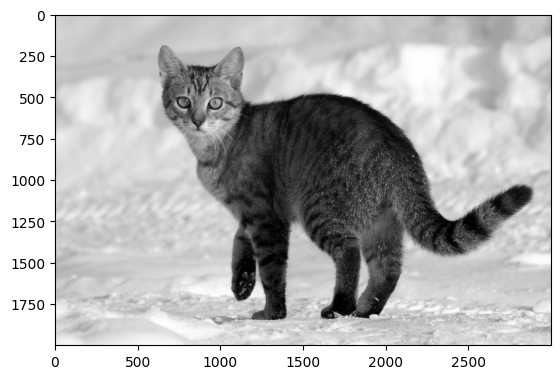

float64


In [ ]:
path = "/content/drive/MyDrive/Colab Notebooks/Bilgisayarla Görme"
im_gray = np.array(Image.open(path + "/kedi.jpeg").convert('L'), np.float64)
imgplot=plt.imshow(im_gray, cmap='gray')
plt.show()
print (str(im_gray.dtype))

In [ ]:
def maxmin_norm(I):
  min_image = min(I.flatten())
  Inorm = I-min_image
  max_image = max(Inorm.flatten())
  Inorm = Inorm/max_image
  Inorm = Inorm*255
  return Inorm

number of objects: 1923


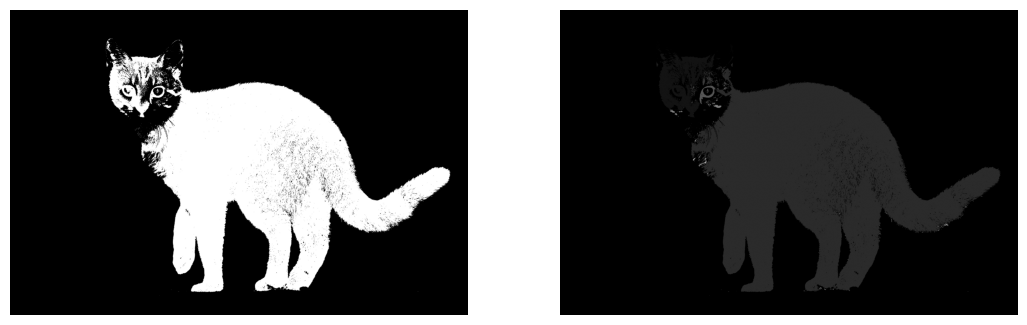

In [ ]:
im_bin = (im_gray <= 120) & (im_gray >=0)
labels, nbr_objects = snd.label(im_bin)
print ("number of objects:", nbr_objects)
fig, ax = plt.subplots (nrows=1, ncols=2, figsize=(13, 13))
ax[0].imshow(maxmin_norm(np.uint8(im_bin)), cmap='gray')
ax[0].axis('off')
ax[1].imshow(maxmin_norm(labels), cmap='gray')
ax[1].axis('off')
plt.show()

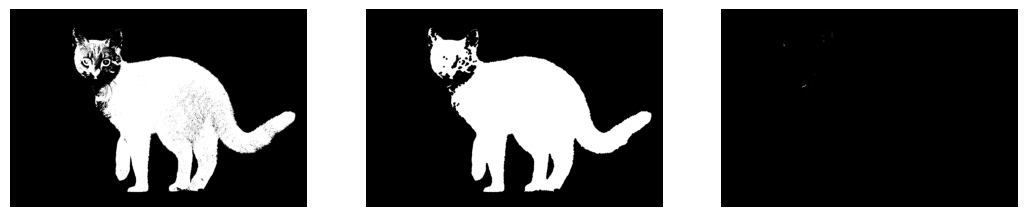

number of objects: 177


In [ ]:
se = np.array([[0, 0, 1, 0, 0,], [0, 1, 1, 1, 0,], [1, 1, 1, 1, 1,], [0, 1, 1, 1, 0,], [0, 0, 1, 0, 0,]])

im_closed = binary_closing(im_bin, se, iterations=5)
labels_closed, nbr_objects_close = snd.label(im_closed)

fig, ax = plt.subplots (nrows=1, ncols=3, figsize=(13, 13))
ax[0].imshow(maxmin_norm(np.uint8(im_bin)), cmap='gray')
ax[0].axis('off')
ax[1].imshow(maxmin_norm(np.uint8(im_closed)), cmap='gray')
ax[1].axis('off')
ax[2].imshow(maxmin_norm(np.uint8(labels_closed)), cmap='gray')
ax[2].axis('off')
plt.show()
print ("number of objects:", nbr_objects_close)

**CANNY EDGE DETECTOR**

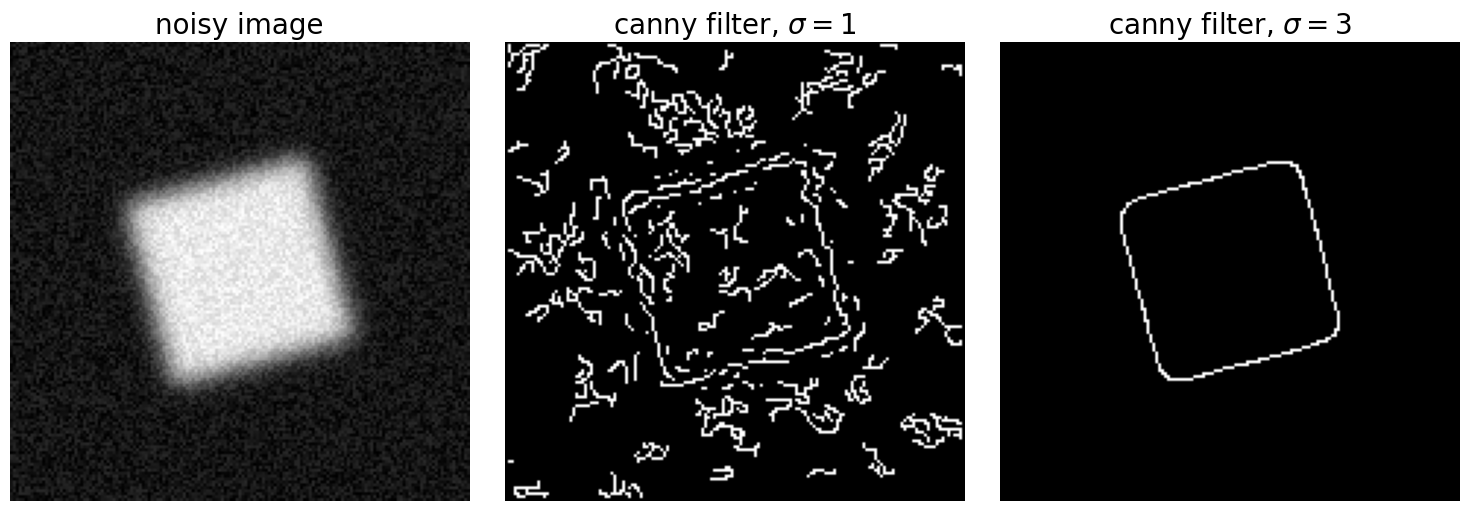

In [ ]:
im = np.zeros((128, 128))
im[32:-32, 32:-32] = 1
im = rotate(im, 15 , mode='constant')
im = gaussian_filter(im, 4)
im += 0.2 * np.random.random(im.shape)
edges1 = feature.canny(im)
edges2 = feature.canny(im, sigma=3)
#display resutls
fig, (ax1, ax2, ax3) = plt.subplots(nrows=1, ncols=3, figsize=(8,3), sharex=True, sharey=True,)
fig.set_figwidth(15)
fig.set_figheight(5)
ax1.imshow(im, cmap=plt.cm.gray)
ax1.axis('off')
ax1.set_title('noisy image', fontsize=20)

ax2.imshow(edges1, cmap='gray')
ax2.axis('off')
ax2.set_title(r'canny filter, $\sigma=1$', fontsize=20)

ax3.imshow(edges2, cmap='gray')
ax3.axis('off')
ax3.set_title(r'canny filter, $\sigma=3$', fontsize=20)

fig.tight_layout()
plt.show()

**LAPLACIAN VERSUS CANNY EDGE DETECTOR**

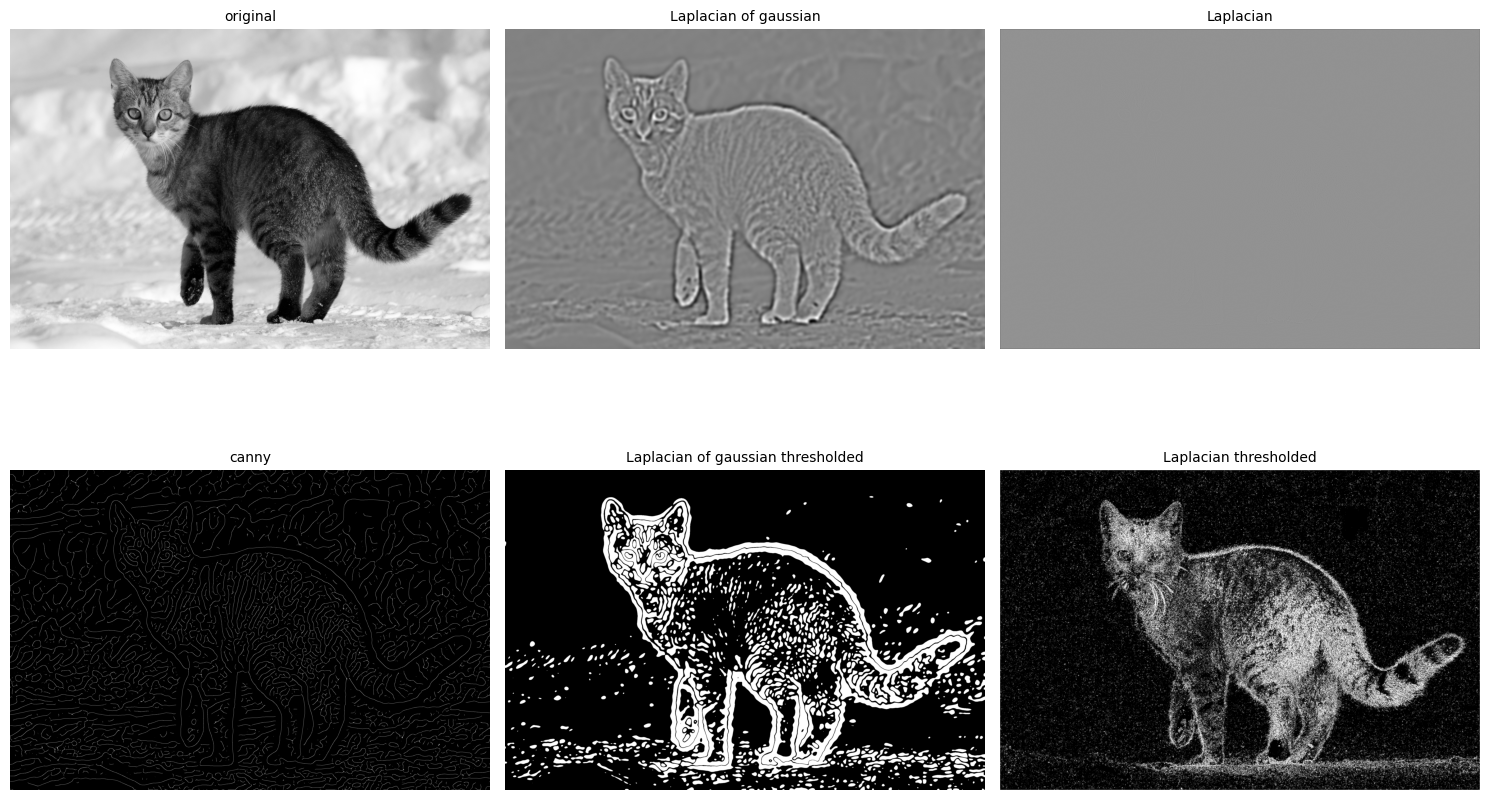

In [ ]:
s_log = gaussian_laplace(im_gray, (11,11))
s_laplace = laplace(im_gray, mode='constant')

T = 1.5*np.sum(np.abs(s_log.flatten()))/s_log.size
s_log_thresh = np.abs(s_log)>T
T = 1.5*np.sum(np.abs(s_laplace.flatten()))/s_laplace.size
s_laplace_thresh =  np.abs(s_laplace)>T
edges_canny = feature.canny(im_gray, sigma=11)

fig, ((ax1, ax2, ax3), (ax4, ax5, ax6)) = plt.subplots(nrows=2, ncols=3, figsize=(8,8), sharex=True, sharey=True,)
fig.set_figwidth(15)
fig.set_figheight(10)
ax1.imshow(im_gray, cmap='gray')
ax1.axis('off')
ax1.set_title('original', fontsize=10)

ax2.imshow(maxmin_norm(s_log), cmap='gray')
ax2.axis('off')
ax2.set_title('Laplacian of gaussian', fontsize=10)

ax3.imshow(maxmin_norm(s_laplace), cmap='gray')
ax3.axis('off')
ax3.set_title(r'Laplacian', fontsize=10)

ax4.imshow(maxmin_norm(np.float64(edges_canny)), cmap='gray')
ax4.axis('off')
ax4.set_title(r'canny', fontsize=10)

ax5.imshow(maxmin_norm(np.float64(s_log_thresh)), cmap='gray')
ax5.axis('off')
ax5.set_title('Laplacian of gaussian thresholded', fontsize=10)

ax6.imshow(maxmin_norm(np.float64(s_laplace_thresh)), cmap='gray')
ax6.axis('off')
ax6.set_title(r'Laplacian thresholded', fontsize=10)

fig.tight_layout()
plt.show()

True
False
255.0
0.0


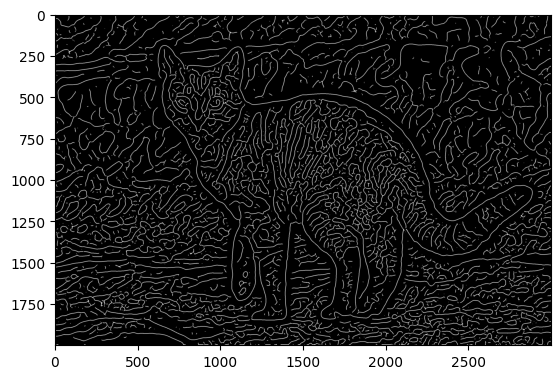

In [ ]:
print(str(edges_canny.flatten().max()))
print(str(edges_canny.flatten().min()))

print(str(maxmin_norm(np.float64(edges_canny)).flatten().max()))
print(str(maxmin_norm(np.float64(edges_canny)).flatten().min()))

#morphology - opening to separate objects better

se = np.array ([[0, 1, 0], [1, 1, 1], [0, 1, 0]])
# binarization
se = se>0
edges_canny_dilated = binary_dilation(edges_canny, se, iterations=1)
imshow(maxmin_norm(np.float64(edges_canny_dilated)), cmap=plt.cm.gray)
fig.tight_layout()
plt.show()

**CORNER DETECTION**

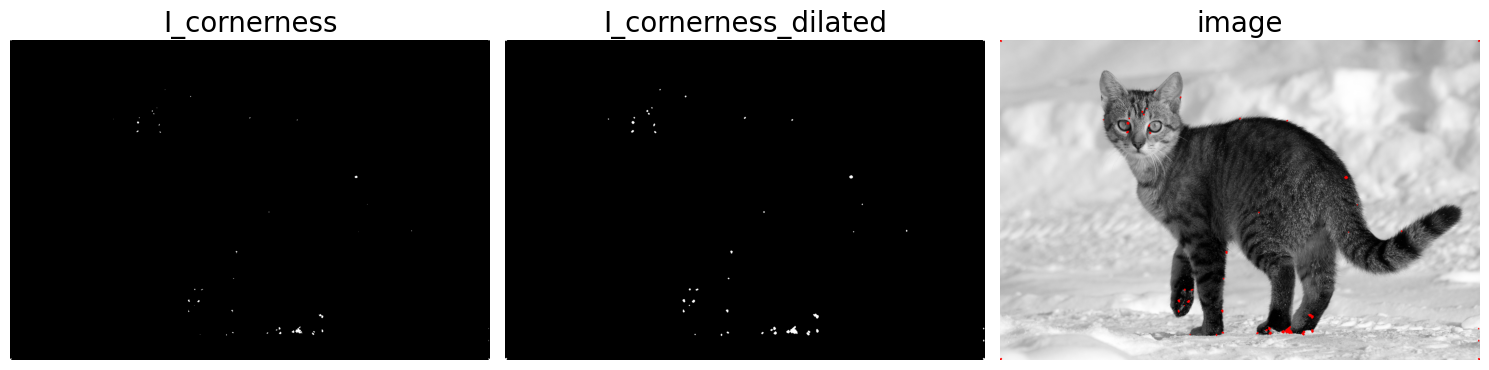

In [ ]:
im_gauss = gaussian_filter(im_gray,3)
sy = sobel (im_gauss, axis=0, mode='constant')
sx = sobel (im_gauss, axis=1, mode='constant')
B1 = np.power(sy,2)
A1 = np.power(sx,2)
C1 = np.multiply(sy,sx)

A = gaussian_filter(A1,3)
B = gaussian_filter(B1,3)
C = gaussian_filter(C1,3)
k = 0.05
corner_det = np.multiply(A,B) - np.power(C,2)
corner_trc = A + B
cornerness = corner_det - k*np.power(corner_trc,2)
c_max = cornerness.max()
c_thersh = 0.00005*c_max
I_cornerness = cornerness > c_thersh
# morphology - openıng to seperare object better
se = np.array([[0, 1, 0],[1, 1, 1],[0, 1, 0]])
#binarization
se = se>0
I_cornerness_dilated = binary_dilation(I_cornerness, se, iterations=3)
im_corner = np.zeros((im_gray.shape[0],im_gray.shape[1],3), dtype='uint8')
im_corner[:,:,0] = im_gray.copy()
im_corner[:,:,1] = im_gray.copy()
im_corner[:,:,2] = im_gray.copy()
im_corner[I_cornerness_dilated] = [255, 0, 0]
fig, ((ax1, ax2, ax3)) = plt.subplots(nrows=1, ncols=3, figsize=(8,8), sharex=True, sharey=True,)

fig.set_figwidth(15)
fig.set_figheight(5)
ax1.imshow(I_cornerness, cmap=plt.cm.gray)
ax1.axis('off')
ax1.set_title('I_cornerness', fontsize=20)
ax2.imshow(I_cornerness_dilated, cmap=plt.cm.gray)
ax2.axis('off')
ax2.set_title('I_cornerness_dilated', fontsize=20)
ax3.imshow(im_corner, cmap=plt.cm.gray)
ax3.axis('off')
ax3.set_title('image', fontsize=20)
fig.tight_layout()
plt.show(block=False)